# Setting up the PyCaret environment

Install PyCaret.
PyCaret 3.3 requires Python 3.9–3.11, so use an environment with one of these versions.

If PyCaret is already installed, skip the next cell.

In [1]:
# Run once in the local environment (PyCaret 3.3 requires Python 3.9-3.11):
# pip install pycaret

Import the required modules.

In [1]:
import pandas as pd
import numpy as np
from pycaret.classification import *

# Preparing the data frame

Load the msk_impact data and convert it to a pandas data frame.

In [2]:
DATA_DIR = "."  # directory containing the input CSV files

In [18]:
df = pd.read_csv(f"{DATA_DIR}/img_path_and_clinical_info_remove_nan_img_feature_0408_remove_dup.csv")

In [19]:
train_ids = pd.read_csv(f"{DATA_DIR}/img_path_and_clinical_info_remove_nan_train_20260408.csv")
train_id = train_ids["patient_id"].to_list()

In [20]:
test_ids = pd.read_csv(f"{DATA_DIR}/img_path_and_clinical_info_remove_nan_test_20260408.csv")
test_id = test_ids["patient_id"].to_list()

In [21]:
df

     Unnamed: 0                                               path  label_x  \
0             0  cropped_slices_RGB_outerline_white_fixed_margi...        0   
1             1  cropped_slices_RGB_outerline_white_fixed_margi...        0   
2             2  cropped_slices_RGB_outerline_white_fixed_margi...        0   
3             3  cropped_slices_RGB_outerline_white_fixed_margi...        0   
4             4  cropped_slices_RGB_outerline_white_fixed_margi...        0   
..          ...                                                ...      ...   
194         194  cropped_slices_RGB_outerline_white_fixed_margi...        1   
195         195  cropped_slices_RGB_outerline_white_fixed_margi...        1   
196         196  cropped_slices_RGB_outerline_white_fixed_margi...        1   
197         197  cropped_slices_RGB_outerline_white_fixed_margi...        1   
198         198  cropped_slices_RGB_outerline_white_fixed_margi...        1   

     patient_id  local_patient_id       WBC       P

When displayed, there are too many columns and some are omitted.<br>
Just in case, check all column names.

In [22]:
print(df.columns)

Index(['Unnamed: 0', 'path', 'label_x', 'patient_id', 'local_patient_id',
       'WBC', 'PLT', 'CRP', 'T-Bil', 'AST',
       ...
       'img_feat_120', 'img_feat_121', 'img_feat_122', 'img_feat_123',
       'img_feat_124', 'img_feat_125', 'img_feat_126', 'img_feat_127', 'src',
       'label_y'],
      dtype='object', length=145)


In [23]:
df

     Unnamed: 0                                               path  label_x  \
0             0  cropped_slices_RGB_outerline_white_fixed_margi...        0   
1             1  cropped_slices_RGB_outerline_white_fixed_margi...        0   
2             2  cropped_slices_RGB_outerline_white_fixed_margi...        0   
3             3  cropped_slices_RGB_outerline_white_fixed_margi...        0   
4             4  cropped_slices_RGB_outerline_white_fixed_margi...        0   
..          ...                                                ...      ...   
194         194  cropped_slices_RGB_outerline_white_fixed_margi...        1   
195         195  cropped_slices_RGB_outerline_white_fixed_margi...        1   
196         196  cropped_slices_RGB_outerline_white_fixed_margi...        1   
197         197  cropped_slices_RGB_outerline_white_fixed_margi...        1   
198         198  cropped_slices_RGB_outerline_white_fixed_margi...        1   

     patient_id  local_patient_id       WBC       P

In [24]:
train_df = df[df["patient_id"].isin(train_id)].copy()

In [25]:
train_df

     Unnamed: 0                                               path  label_x  \
0             0  cropped_slices_RGB_outerline_white_fixed_margi...        0   
2             2  cropped_slices_RGB_outerline_white_fixed_margi...        0   
4             4  cropped_slices_RGB_outerline_white_fixed_margi...        0   
7             7  cropped_slices_RGB_outerline_white_fixed_margi...        0   
8             8  cropped_slices_RGB_outerline_white_fixed_margi...        0   
..          ...                                                ...      ...   
193         193  cropped_slices_RGB_outerline_white_fixed_margi...        1   
194         194  cropped_slices_RGB_outerline_white_fixed_margi...        1   
196         196  cropped_slices_RGB_outerline_white_fixed_margi...        1   
197         197  cropped_slices_RGB_outerline_white_fixed_margi...        1   
198         198  cropped_slices_RGB_outerline_white_fixed_margi...        1   

     patient_id  local_patient_id       WBC       P

In [26]:
test_df = df[df["patient_id"].isin(test_id)].copy()
test_df = test_df[~test_df["patient_id"].isin([87, 97])]

In [27]:
test_df

     Unnamed: 0                                               path  label_x  \
1             1  cropped_slices_RGB_outerline_white_fixed_margi...        0   
3             3  cropped_slices_RGB_outerline_white_fixed_margi...        0   
5             5  cropped_slices_RGB_outerline_white_fixed_margi...        0   
6             6  cropped_slices_RGB_outerline_white_fixed_margi...        0   
11           11  cropped_slices_RGB_outerline_white_fixed_margi...        0   
19           19  cropped_slices_RGB_outerline_white_fixed_margi...        0   
22           22  cropped_slices_RGB_outerline_white_fixed_margi...        0   
26           26  cropped_slices_RGB_outerline_white_fixed_margi...        0   
27           27  cropped_slices_RGB_outerline_white_fixed_margi...        0   
30           30  cropped_slices_RGB_outerline_white_fixed_margi...        0   
34           34  cropped_slices_RGB_outerline_white_fixed_margi...        0   
40           40  cropped_slices_RGB_outerline_white_

There are too many variables, so extract only the columns needed for building the model.

Here, the prediction target is whether the patient dies within 12 months of diagnosis.<br>
Add a column storing the ground-truth label to df_estim above.

Here, remove the variables that define the ground-truth label (here, survival time and survival/death status).

In [28]:
df_estim = df.drop(
    ['Unnamed: 0', 'patient_id', 'local_patient_id', 'src', 'label_y'],
    axis=1
)

# Remove columns containing "img"
df_estim = df_estim.loc[:, ~df_estim.columns.str.contains('img')]

In [29]:
train_df = train_df.drop(
    ['Unnamed: 0', 'patient_id', 'local_patient_id', 'src', 'label_y'],
    axis=1
)

# Remove columns containing "img"
train_estim = train_df.loc[:, ~train_df.columns.str.contains('img')]

In [30]:
train_estim

                                                  path  label_x       WBC  \
0    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.518660   
2    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.049564   
4    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.762637   
7    cropped_slices_RGB_outerline_white_fixed_margi...        0 -1.247841   
8    cropped_slices_RGB_outerline_white_fixed_margi...        0 -1.575894   
..                                                 ...      ...       ...   
193  cropped_slices_RGB_outerline_white_fixed_margi...        1  2.301810   
194  cropped_slices_RGB_outerline_white_fixed_margi...        1  1.490518   
196  cropped_slices_RGB_outerline_white_fixed_margi...        1  0.993527   
197  cropped_slices_RGB_outerline_white_fixed_margi...        1  0.771551   
198  cropped_slices_RGB_outerline_white_fixed_margi...        1  0.384567   

          PLT       CRP     T-Bil       AST       ALT      γGTP       ALP  

In [31]:
test_df = test_df.drop(
    ['Unnamed: 0', 'patient_id', 'local_patient_id', 'src', 'label_y'],
    axis=1
)

# Remove columns containing "img"
test_estim = test_df.loc[:, ~test_df.columns.str.contains('img')]

In [32]:
test_estim

                                                  path  label_x       WBC  \
1    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.974791   
3    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.725313   
5    cropped_slices_RGB_outerline_white_fixed_margi...        0 -1.116227   
6    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.149747   
11   cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.361901   
19   cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.493515   
22   cropped_slices_RGB_outerline_white_fixed_margi...        0  0.017226   
26   cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.191000   
27   cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.558340   
30   cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.346186   
34   cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.774423   
40   cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.860856   

In [33]:
df_estim["label_x"].value_counts()

,count
label_x,
1,100
0,99


In [34]:
df_estim

                                                  path  label_x       WBC  \
0    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.518660   
1    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.974791   
2    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.049564   
3    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.725313   
4    cropped_slices_RGB_outerline_white_fixed_margi...        0 -0.762637   
..                                                 ...      ...       ...   
194  cropped_slices_RGB_outerline_white_fixed_margi...        1  1.490518   
195  cropped_slices_RGB_outerline_white_fixed_margi...        1 -0.632987   
196  cropped_slices_RGB_outerline_white_fixed_margi...        1  0.993527   
197  cropped_slices_RGB_outerline_white_fixed_margi...        1  0.771551   
198  cropped_slices_RGB_outerline_white_fixed_margi...        1  0.384567   

          PLT       CRP     T-Bil       AST       ALT      γGTP       ALP  

In [35]:
# Keep aside
patient_ids = df_estim["path"].copy()

# Training data
X = df_estim.drop(columns=["path"])

In [36]:
X

     label_x       WBC       PLT       CRP     T-Bil       AST       ALT  \
0          0 -0.518660  0.808068 -0.684757 -0.657096 -0.317251 -0.319587   
1          0 -0.974791  0.133618 -0.691023 -0.458172 -0.356454 -0.262354   
2          0 -0.049564  0.841238 -0.687890 -0.358710 -0.356454 -0.331034   
3          0 -0.725313  2.002176 -0.675358 -0.856020 -0.366255 -0.342480   
4          0 -0.762637  0.122562 -0.693112 -0.458172 -0.248645 -0.273801   
..       ...       ...       ...       ...       ...       ...       ...   
194        1  1.490518 -1.480638 -0.616875 -0.557634 -0.238845 -0.273801   
195        1 -0.632987 -0.319700  0.527720 -0.657096  0.143385  0.309972   
196        1  0.993527  0.222071  0.790893 -0.955482 -0.405458 -0.388266   
197        1  0.771551 -1.071546  1.669181  0.238062 -0.121235 -0.216568   
198        1  0.384567 -1.049433  0.748075 -0.259248 -0.327052 -0.331034   

         γGTP       ALP       Cre    PT-INR  
0   -0.555147  0.498105 -0.521672 -0.3805

In [37]:
# Keep aside
train_patient_ids = train_estim["path"].copy()

# Training data
train_X = train_estim.drop(columns=["path"])

test_patient_ids = test_estim["path"].copy()

# Training data
test_X = test_estim.drop(columns=["path"])

In [38]:
train_X

     label_x       WBC       PLT       CRP     T-Bil       AST       ALT  \
0          0 -0.518660  0.808068 -0.684757 -0.657096 -0.317251 -0.319587   
2          0 -0.049564  0.841238 -0.687890 -0.358710 -0.356454 -0.331034   
4          0 -0.762637  0.122562 -0.693112 -0.458172 -0.248645 -0.273801   
7          0 -1.247841  0.244184 -0.614786 -0.756558  0.457010  1.076890   
8          0 -1.575894 -0.463435 -0.654471 -0.955482 -0.278048 -0.216568   
..       ...       ...       ...       ...       ...       ...       ...   
193        1  2.301810 -0.408153  1.857162  0.536449 -0.219243 -0.262354   
194        1  1.490518 -1.480638 -0.616875 -0.557634 -0.238845 -0.273801   
196        1  0.993527  0.222071  0.790893 -0.955482 -0.405458 -0.388266   
197        1  0.771551 -1.071546  1.669181  0.238062 -0.121235 -0.216568   
198        1  0.384567 -1.049433  0.748075 -0.259248 -0.327052 -0.331034   

         γGTP       ALP       Cre    PT-INR  
0   -0.555147  0.498105 -0.521672 -0.3805

In [39]:
test_X

     label_x       WBC       PLT       CRP     T-Bil       AST        ALT  \
1          0 -0.974791  0.133618 -0.691023 -0.458172 -0.356454  -0.262354   
3          0 -0.725313  2.002176 -0.675358 -0.856020 -0.366255  -0.342480   
5          0 -1.116227  1.283500 -0.683713 -0.955482 -0.317251  -0.353927   
6          0 -0.149747 -0.529775 -0.490510 -0.657096 -0.307450  -0.342480   
11         0 -0.361901  0.620107 -0.689979 -0.557634 -0.297649  -0.262354   
19         0 -0.493515  0.299467 -0.676402 -0.756558 -0.278048  -0.273801   
22         0  0.017226 -0.795132 -0.492599 -0.358710 -0.258446  -0.342480   
26         0 -0.191000  0.222071 -0.675358 -0.557634 -0.258446  -0.262354   
27         0 -0.558340  4.777370 -0.692067  0.436987 -0.238845  -0.250908   
30         0 -0.346186  1.150821 -0.681624 -0.159786 -0.209442  -0.170782   
34         0 -0.774423  0.542711 -0.673269 -0.856020 -0.258446  -0.250908   
40         0 -0.860856 -0.397096 -0.659693 -0.159786 -0.287848  -0.342480   

# Comparison and selection of prediction models

From here we proceed with machine learning.<br>
First, load the data and run setup.

In [40]:
clf = setup(
    data=train_X,
    target="label_x",
    test_data=test_X,
    fold_strategy="stratifiedkfold",
    fold=5,
    session_id=42
)

,Description,Value
0,Session id,42
1,Target,label_x
2,Target type,Binary
3,Original data shape,"(197, 11)"
4,Transformed data shape,"(197, 11)"
5,Transformed train set shape,"(139, 11)"
6,Transformed test set shape,"(58, 11)"
7,Numeric features,10
8,Preprocess,True
9,Imputation type,simple


This is where PyCaret shines: it compares multiple models automatically.

In [41]:
compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
et,Extra Trees Classifier,0.9283,0.9691,0.8857,0.9714,0.9246,0.8566,0.8627,0.3000
rf,Random Forest Classifier,0.8997,0.9609,0.8857,0.9204,0.8990,0.7995,0.8060,0.2260
ada,Ada Boost Classifier,0.8995,0.9544,0.8857,0.9110,0.8979,0.7989,0.7996,0.1220
gbc,Gradient Boosting Classifier,0.8995,0.9615,0.8857,0.9159,0.8988,0.7991,0.8026,0.2420
xgboost,Extreme Gradient Boosting,0.8995,0.9608,0.8714,0.9294,0.8977,0.7991,0.8035,0.1420
lightgbm,Light Gradient Boosting Machine,0.8995,0.9604,0.9000,0.9105,0.9009,0.7991,0.8080,0.1260
nb,Naive Bayes,0.8992,0.9573,0.8714,0.9270,0.8966,0.7982,0.8023,0.0340
qda,Quadratic Discriminant Analysis,0.8849,0.9620,0.8714,0.8990,0.8828,0.7697,0.7735,0.0400
knn,K Neighbors Classifier,0.8706,0.9383,0.7571,0.9857,0.8423,0.7416,0.7698,0.0660
lr,Logistic Regression,0.8704,0.9620,0.8143,0.9258,0.8618,0.7410,0.7525,2.3860


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

ExtraTreesClassifier(bootstrap=False, ccp_alpha=0.0, class_weight=None,
                     criterion='gini', max_depth=None, max_features='sqrt',
                     max_leaf_nodes=None, max_samples=None,
                     min_impurity_decrease=0.0, min_samples_leaf=1,
                     min_samples_split=2, min_weight_fraction_leaf=0.0,
                     monotonic_cst=None, n_estimators=100, n_jobs=-1,
                     oob_score=False, random_state=42, verbose=0,
                     warm_start=False)

Choose the model to build, referring to the comparison above.<br>
The evaluation metrics (columns) are briefly explained below.<br>
<br>
Accuracy: the proportion of predictions that were correct.<br>
AUC (Area Under the Curve): the area under the ROC curve, which plots Recall against Specificity while varying the positive/negative threshold.<br>
Recall (true positive rate, sensitivity): the proportion of actual positives that were correctly predicted as positive.<br>
Precision: the proportion of predicted positives that were actually positive.<br>
F1 (F1-score): a metric that takes both Precision and Recall into account.<br>
Kappa (Cohen's kappa): a statistic for the agreement between two ratings of the same subjects.<br>
MCC (Matthews correlation coefficient): a metric for binary classification, used when either the positive or negative class is in the minority.<br>
<br>

Here, we focus on the Decision Tree Classifier.

In [44]:
model = create_model('et')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8929,0.9541,0.7857,1.0000,0.8800,0.7857,0.8044
1,0.9286,0.9566,0.9286,0.9286,0.9286,0.8571,0.8571
2,0.9286,0.9847,0.9286,0.9286,0.9286,0.8571,0.8571
3,0.9286,0.9719,0.8571,1.0000,0.9231,0.8571,0.8660
4,0.9630,0.9780,0.9286,1.0000,0.9630,0.9260,0.9286
Mean,0.9283,0.9691,0.8857,0.9714,0.9246,0.8566,0.8627
Std,0.0222,0.0119,0.0571,0.0350,0.0264,0.0444,0.0395


Processing:   0%|          | 0/4 [00:00<?, ?it/s]

For reference, the arguments corresponding to each model are as follows.

‘lr’ - Logistic Regression

‘knn’ - K Neighbors Classifier

‘nb’ - Naive Bayes

‘dt’ - Decision Tree Classifier

‘svm’ - SVM - Linear Kernel

‘rbfsvm’ - SVM - Radial Kernel

‘gpc’ - Gaussian Process Classifier

‘mlp’ - MLP Classifier

‘ridge’ - Ridge Classifier

‘rf’ - Random Forest Classifier

‘qda’ - Quadratic Discriminant Analysis

‘ada’ - Ada Boost Classifier

‘gbc’ - Gradient Boosting Classifier

‘lda’ - Linear Discriminant Analysis

‘et’ - Extra Trees Classifier

‘xgboost’ - Extreme Gradient Boosting

‘lightgbm’ - Light Gradient Boosting Machine

‘catboost’ - CatBoost Classifier

Next, optimize the hyperparameters.<br>
* This takes a while. Have a coffee and wait.

In [45]:
tuned_model = tune_model(model, n_iter = 15, optimize = 'Recall')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.8929,0.9592,0.7857,1.0000,0.8800,0.7857,0.8044
1,0.8929,0.9388,0.7857,1.0000,0.8800,0.7857,0.8044
2,0.9286,0.9898,0.9286,0.9286,0.9286,0.8571,0.8571
3,0.9286,0.9847,0.8571,1.0000,0.9231,0.8571,0.8660
4,0.9259,0.9670,0.8571,1.0000,0.9231,0.8525,0.8619
Mean,0.9138,0.9679,0.8429,0.9857,0.9069,0.8276,0.8388
Std,0.0171,0.0184,0.0535,0.0286,0.0221,0.0343,0.0282


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 5 folds for each of 15 candidates, totalling 75 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


In [46]:
evaluate_model(tuned_model)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

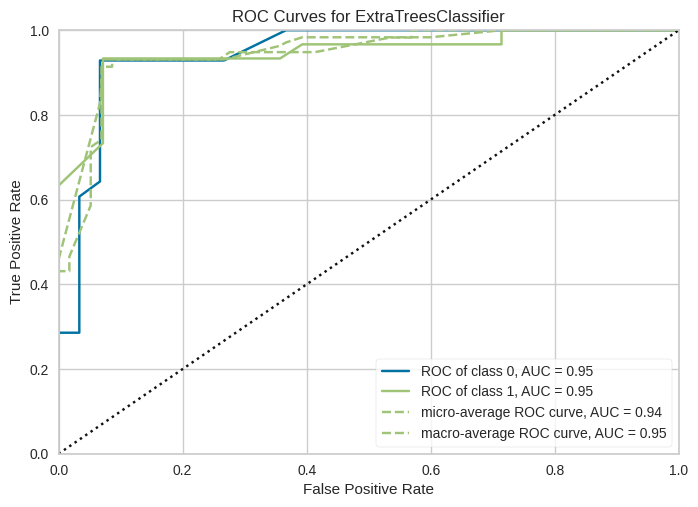

In [47]:
plot_model(tuned_model, plot="auc")

## Evaluation with confidence intervals

Add 95% confidence intervals to the results of the 58 test patients (one prediction per patient).

- accuracy / sensitivity / specificity / PPV / NPV: Wilson score interval (confidence interval for a proportion)
- AUC / F1: stratified bootstrap (patients resampled with replacement within positives and negatives separately, 2000 resamples, percentile method)
- The threshold is fixed at 0.5 (same as PyCaret's `prediction_label`)

In [ ]:
# ===== Functions for metrics and 95% confidence intervals =====
# Proportion metrics use the Wilson score interval; AUC and F1 use a stratified bootstrap (percentile method).
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score

THRESHOLD = 0.5
N_BOOT = 2000
SEED = 42

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

def bootstrap_ci(y_true, y_prob, stat_fn, n_boot=N_BOOT, seed=SEED):
    # Resample within each class so that every bootstrap sample contains both positives and negatives
    rng = np.random.default_rng(seed)
    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)])
        vals.append(stat_fn(y_true[idx], y_prob[idx]))
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)

def compute_metrics(y_true, y_prob, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    f1_fn = lambda yt, yp: f1_score(yt, (yp >= threshold).astype(int), zero_division=0)
    rows = [
        ("AUC", roc_auc_score(y_true, y_prob), *bootstrap_ci(y_true, y_prob, roc_auc_score)),
        ("accuracy", (tp + tn) / len(y_true), *wilson_ci(tp + tn, len(y_true))),
        ("sensitivity", tp / (tp + fn), *wilson_ci(tp, tp + fn)),
        ("specificity", tn / (tn + fp), *wilson_ci(tn, tn + fp)),
        ("PPV", tp / (tp + fp) if tp + fp > 0 else np.nan, *wilson_ci(tp, tp + fp)),
        ("NPV", tn / (tn + fn) if tn + fn > 0 else np.nan, *wilson_ci(tn, tn + fn)),
        ("F1", f1_fn(y_true, y_prob), *bootstrap_ci(y_true, y_prob, f1_fn)),
    ]
    df = pd.DataFrame(rows, columns=["metric", "value", "ci_low", "ci_high"])
    df["value_95ci"] = df.apply(lambda r: f"{r['value']:.3f} ({r['ci_low']:.3f}-{r['ci_high']:.3f})", axis=1)
    counts = {"n": len(y_true), "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    return df, counts

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Extra Trees Classifier,0.9138,0.9458,0.9000,0.9310,0.9153,0.8276,0.8281


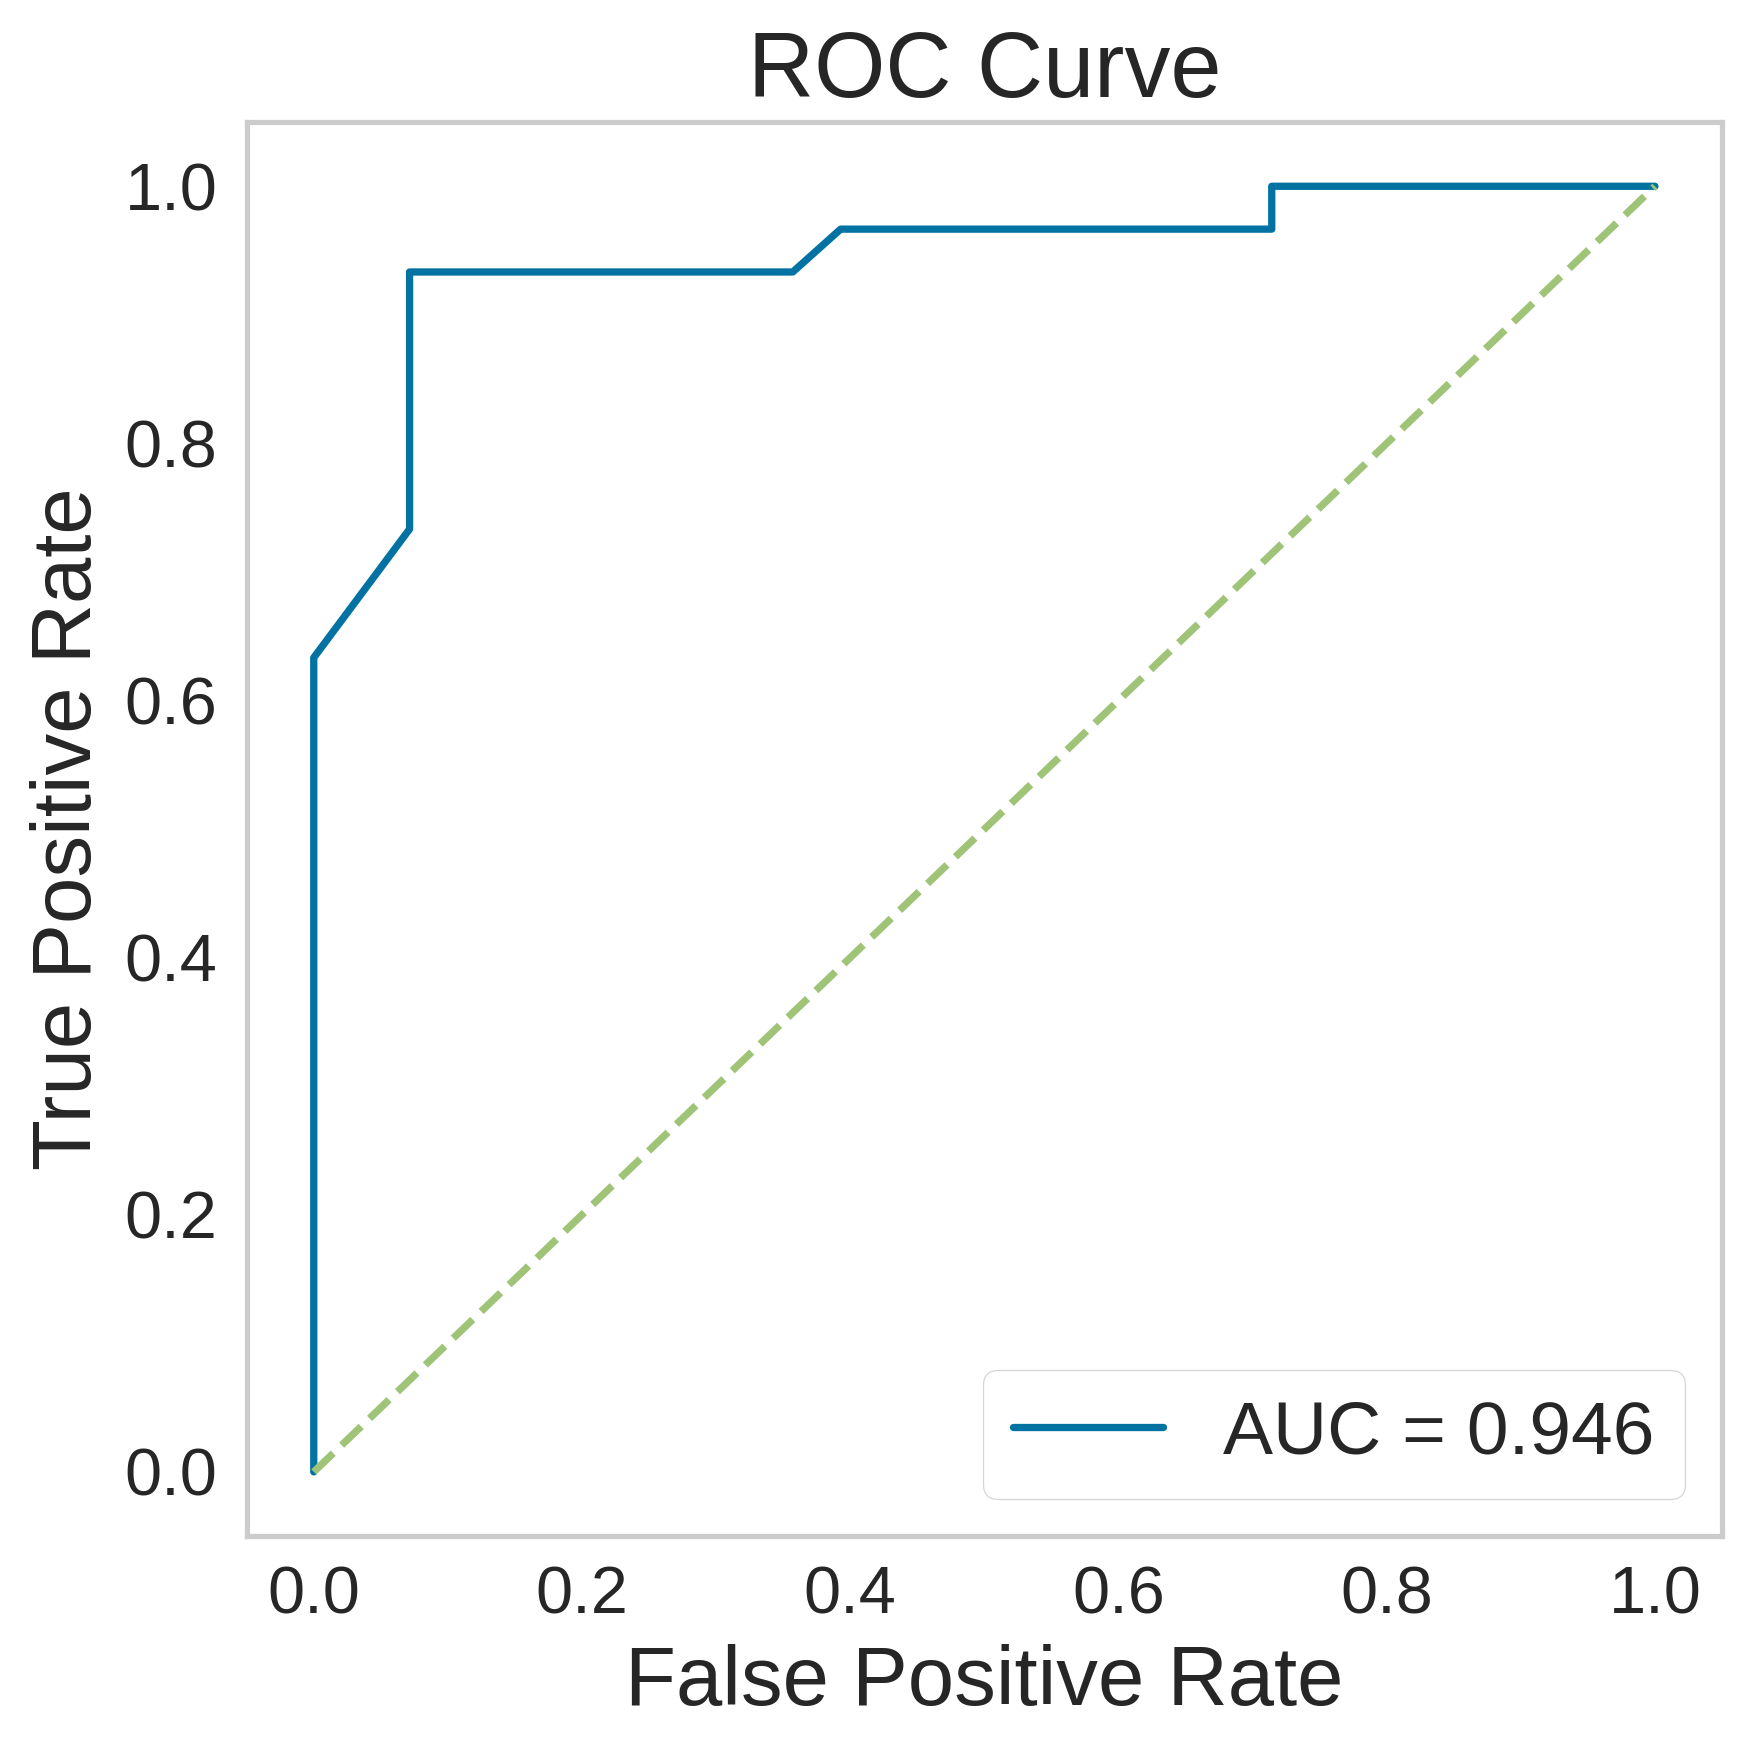

In [48]:
from pycaret.classification import predict_model
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt


# ===== Test prediction =====
pred = predict_model(tuned_model, raw_score=True)


y_true = pred["label_x"]
y_score = pred["prediction_score_1"]

# ===== ROC =====
fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)
auc_lo, auc_hi = bootstrap_ci(np.asarray(y_true).astype(int), np.asarray(y_score, dtype=float), roc_auc_score)

# ===== plot =====
plt.figure(figsize=(6,6), dpi=300)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}\n(95% CI {auc_lo:.3f}-{auc_hi:.3f})")
plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate", fontsize=20)
plt.ylabel("True Positive Rate", fontsize=20)
plt.title("ROC Curve", fontsize=22)
plt.tick_params(axis='both', labelsize=16)
plt.legend(fontsize=18, loc="lower right", frameon=True)
plt.grid()

plt.tight_layout()
plt.show()

In [49]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# ===== Predicted probabilities =====
# train
train_pred = predict_model(tuned_model, data=train_X, raw_score=True, verbose=False)
train_prob = train_pred["prediction_score_1"].values
train_label = train_pred["label_x"].values

# test
test_pred = predict_model(tuned_model, data=test_X, raw_score=True, verbose=False)
test_prob = test_pred["prediction_score_1"].values
test_label = test_pred["label_x"].values

# ===== ROC =====
fpr_train, tpr_train, _ = roc_curve(train_label, train_prob)
fpr_test,  tpr_test,  _ = roc_curve(test_label,  test_prob)

auc_train = auc(fpr_train, tpr_train)
auc_test  = auc(fpr_test,  tpr_test)

# ===== plot =====
plt.figure(figsize=(6,6), dpi=300)

plt.plot(fpr_train, tpr_train, label=f"Train AUC = {auc_train:.3f}")
plt.plot(fpr_test,  tpr_test,  label=f"Test AUC = {auc_test:.3f}")

# Diagonal (random)
plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate", fontsize=14)
plt.ylabel("True Positive Rate", fontsize=14)
plt.title("ROC Curve", fontsize=16)
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

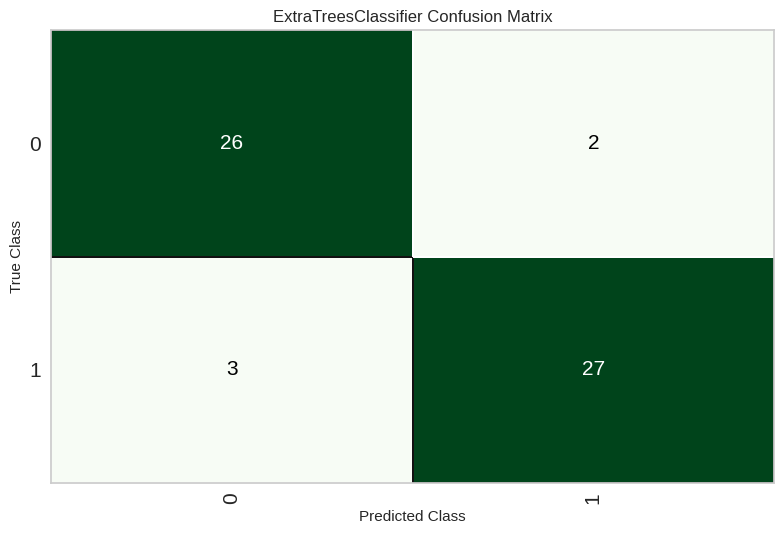

In [50]:
plot_model(tuned_model, plot="confusion_matrix")

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Extra Trees Classifier,0.9138,0.9458,0.9000,0.9310,0.9153,0.8276,0.8281


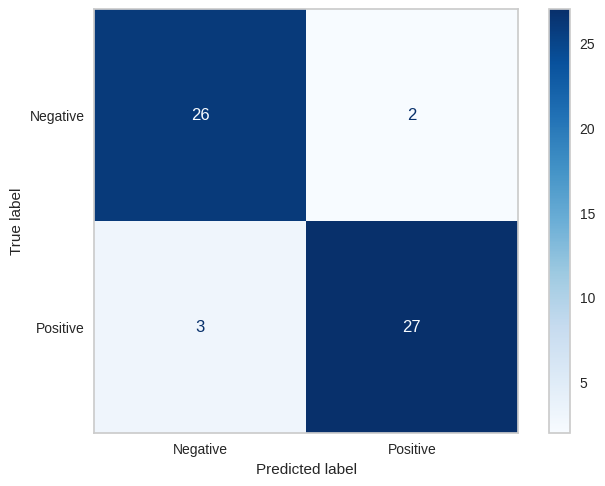

In [51]:
from pycaret.classification import predict_model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict with PyCaret
pred_df = predict_model(tuned_model)

# Extract
y_true = pred_df["label_x"]        # ← ground-truth labels
y_pred = pred_df["prediction_label"]

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot (in the same style as the other figures)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive'],

)

disp.plot(cmap=plt.cm.Blues)
#plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

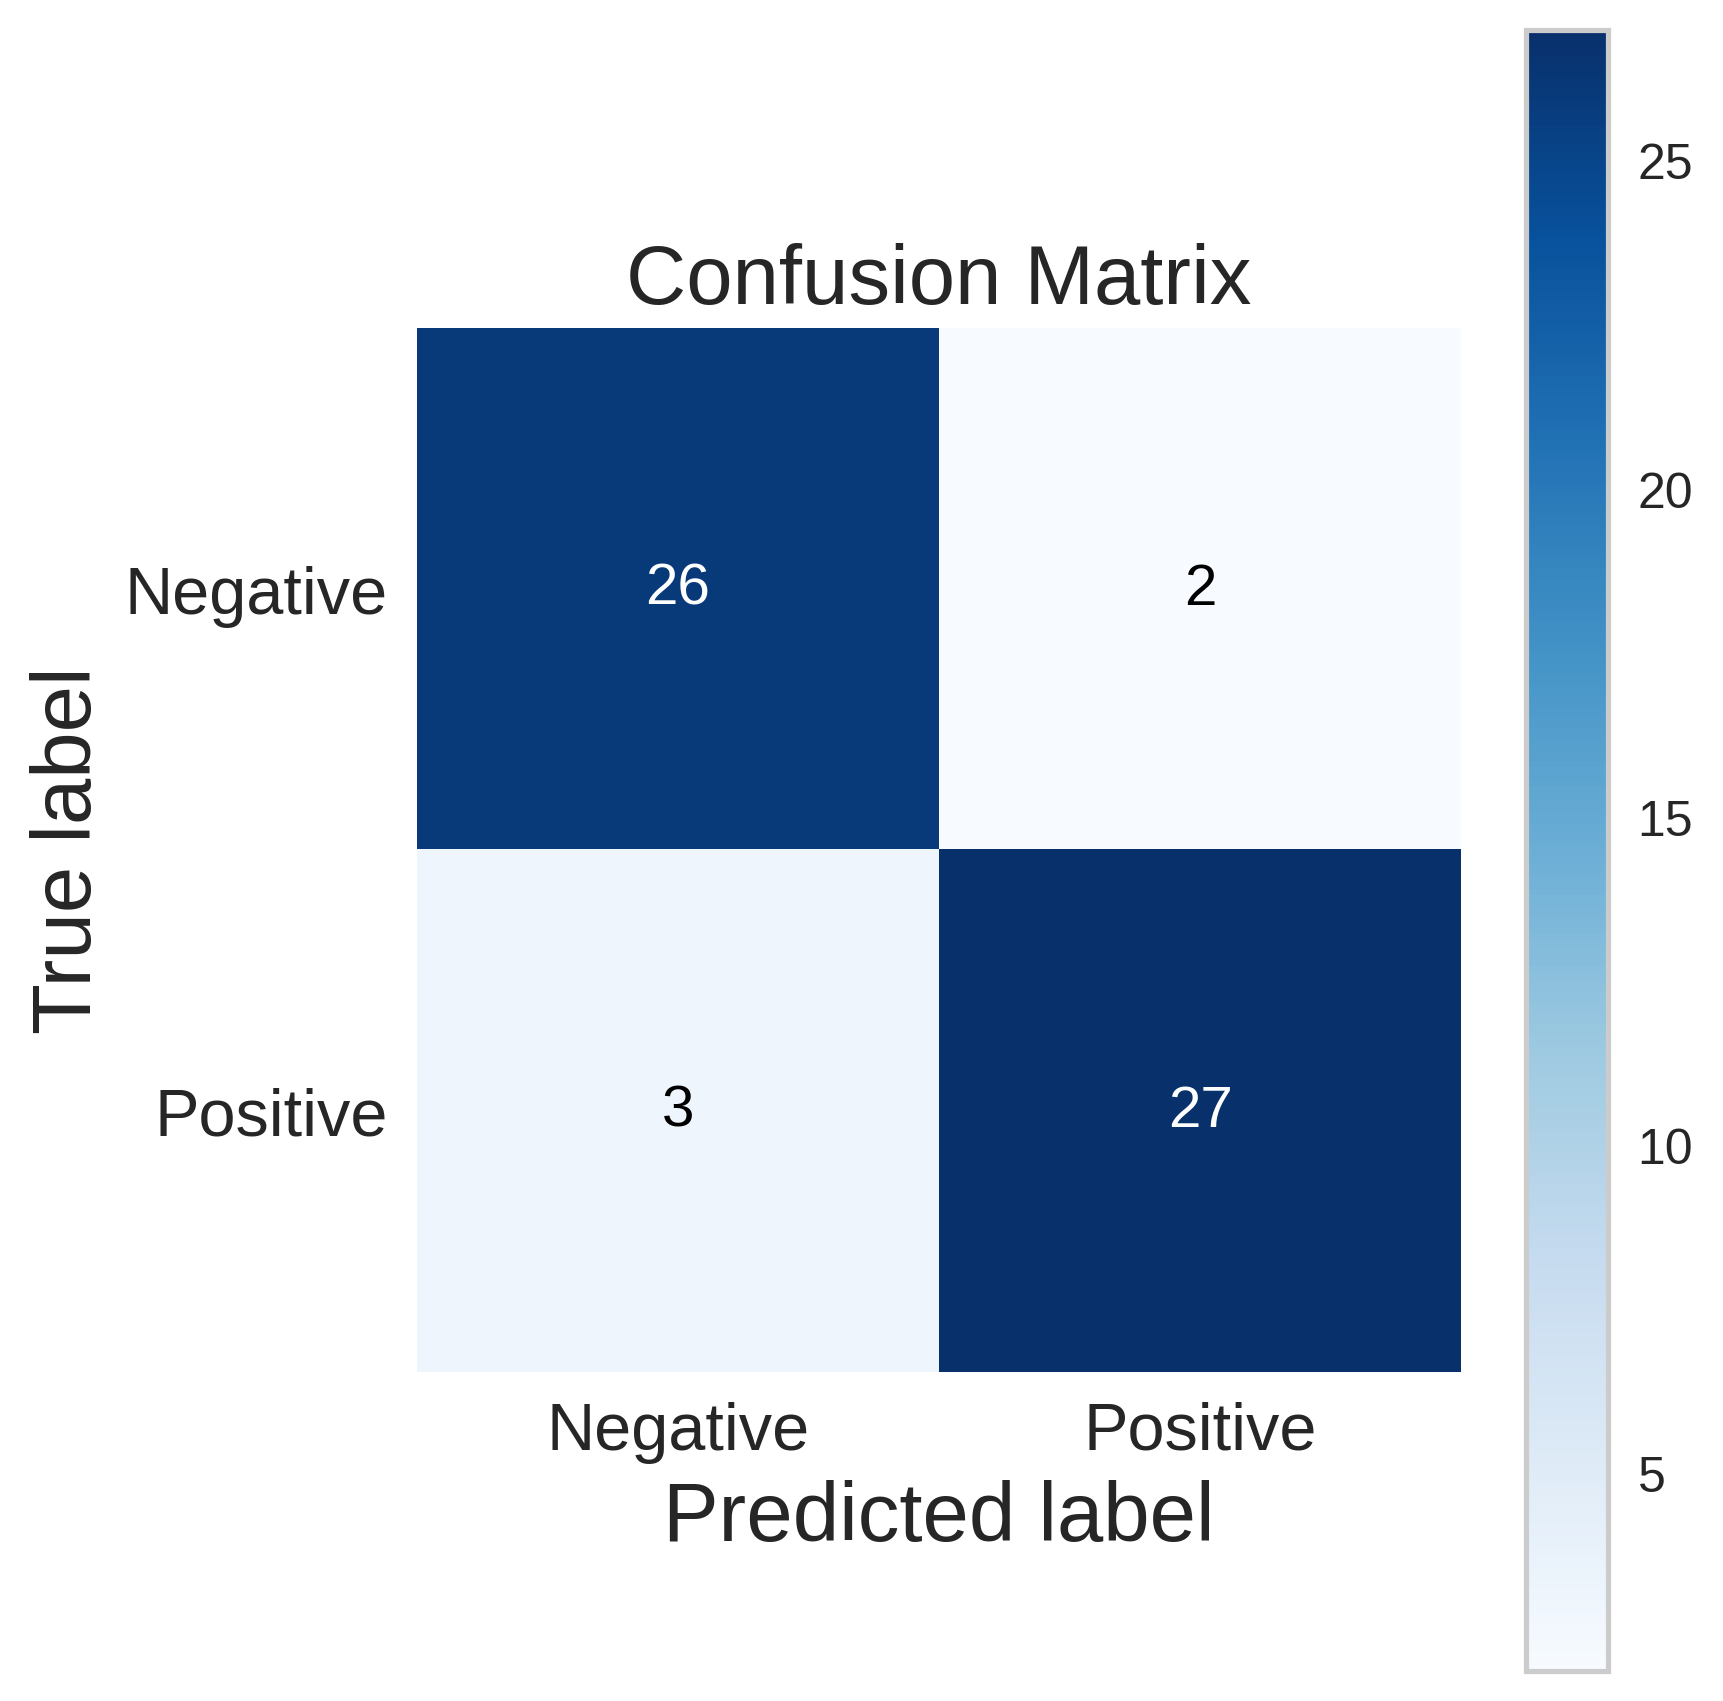

In [52]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

# ===== confusion matrix =====
cm = confusion_matrix(y_true, y_pred)

# ===== figure =====
fig, ax = plt.subplots(figsize=(6, 6), dpi=300)

# ===== heatmap =====
im = ax.imshow(cm, cmap=plt.cm.Blues)

# ===== Draw text =====
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text = ax.text(
            j, i, cm[i, j],
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max()/2 else "black",
            fontsize=14  # ← specified font size
        )

# ===== Axis settings =====
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Negative', 'Positive'], fontsize=16)
ax.set_yticklabels(['Negative', 'Positive'], fontsize=16)

ax.set_xlabel("Predicted label", fontsize=20)
ax.set_ylabel("True label", fontsize=20)

# ===== Remove grid and frame =====
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)

# ===== Color bar =====
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=12)

# ===== Title =====
ax.set_title("Confusion Matrix", fontsize=20)

plt.tight_layout()
plt.show()

In [ ]:
# ===== Metrics with 95% confidence intervals (58 test patients) =====
pred_ci = predict_model(tuned_model, raw_score=True, verbose=False)
df_metrics, counts = compute_metrics(pred_ci["label_x"].values, pred_ci["prediction_score_1"].values)
print(counts)
display(df_metrics[["metric", "value_95ci", "value", "ci_low", "ci_high"]].round(3))

df_metrics.assign(**counts).to_csv(
    f"{DATA_DIR}/fig3_only_blood_test_metrics_95ci.csv",
    index=False,
)

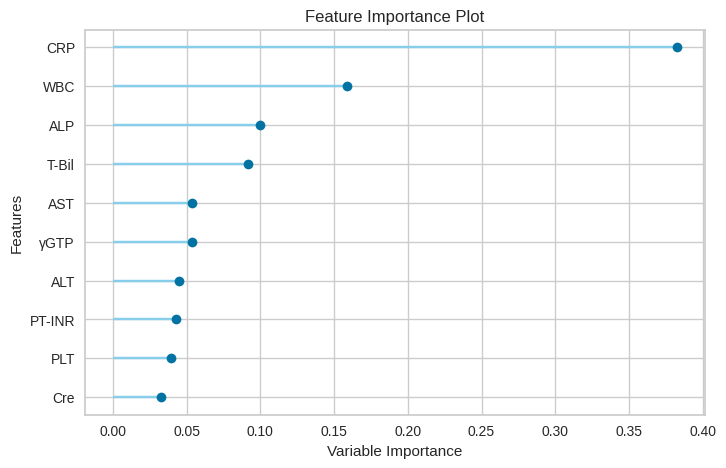

In [53]:
plot_model(tuned_model, plot="feature")

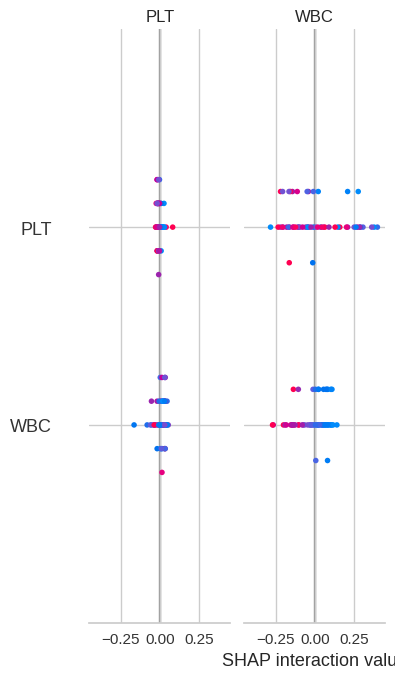

In [54]:
interpret_model(tuned_model)

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

# 1) Finalize the model
model_final = finalize_model(tuned_model)

# 2) Get the underlying RandomForest
rf = model_final.named_steps["actual_estimator"]

# 3) Get the feature names used in training
feature_names = get_config("X_train").columns

# 4) feature importance
fi = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(fi.head(20))

  Feature  Importance
2     CRP    0.365114
0     WBC    0.157479
3   T-Bil    0.098545
7     ALP    0.090141
4     AST    0.060865
9  PT-INR    0.053282
5     ALT    0.049132
6    γGTP    0.048544
1     PLT    0.045534
8     Cre    0.031363

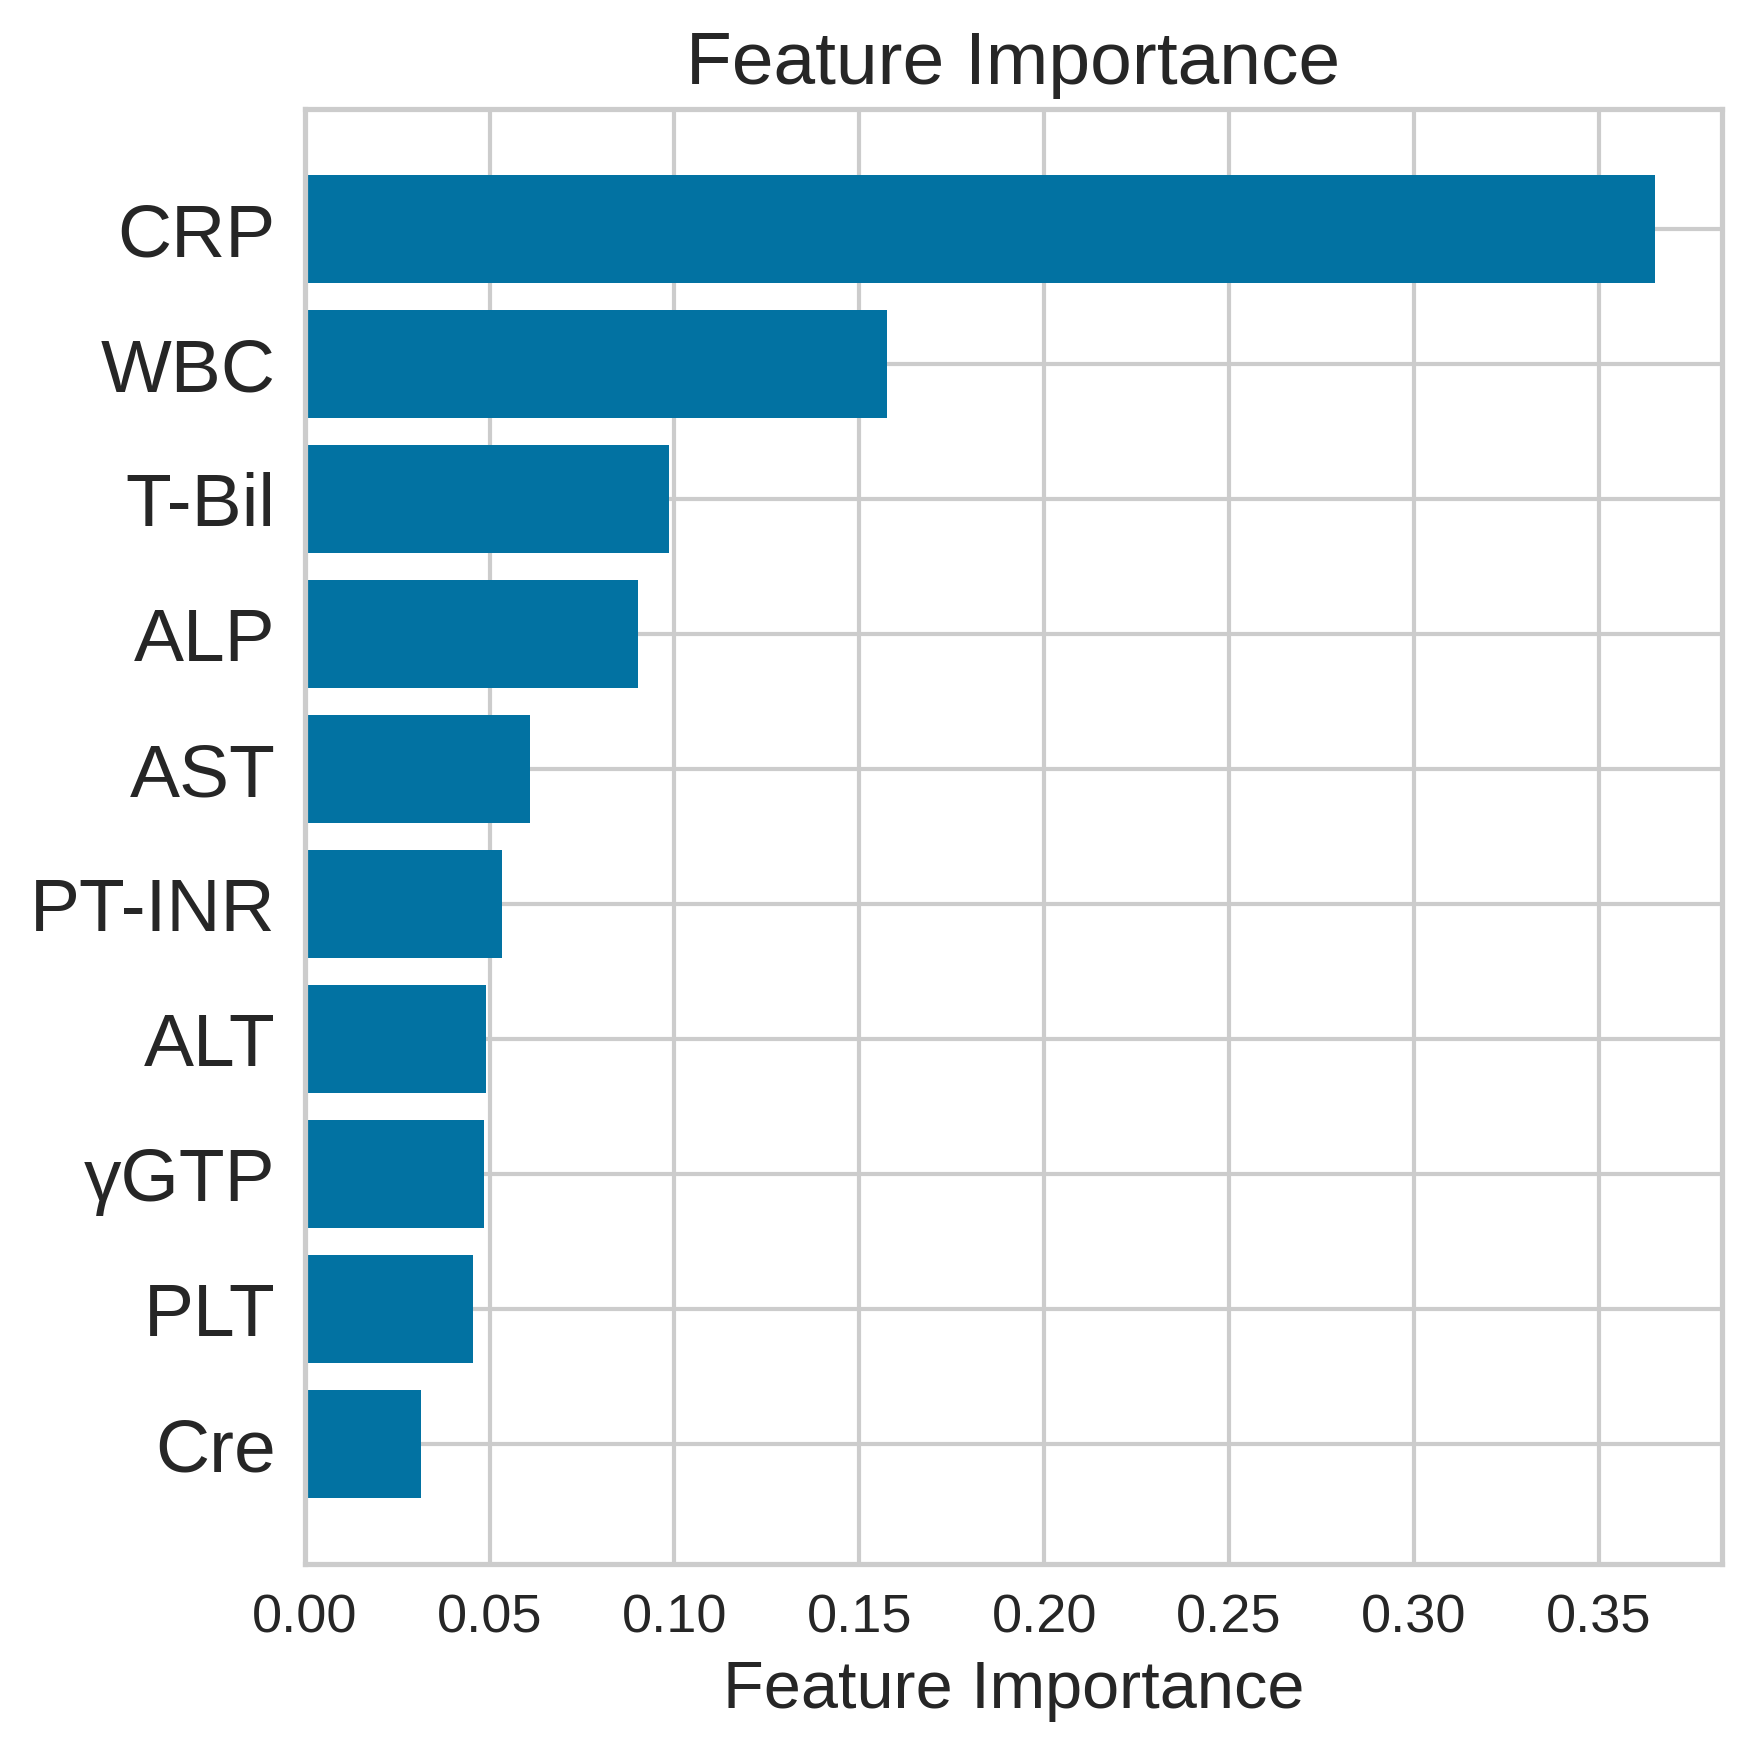

In [56]:
import matplotlib.pyplot as plt

# ===== Sort (so that the most important features are at the top) =====
fi_plot = fi.sort_values("Importance", ascending=True)

# ===== Plot =====
plt.figure(figsize=(6, 6), dpi=300)

plt.barh(fi_plot["Feature"], fi_plot["Importance"])

plt.xlabel("Feature Importance", fontsize=16)
plt.title("Feature Importance", fontsize=18)

plt.xticks(fontsize=13)
plt.yticks(fontsize=18)

plt.tight_layout()
plt.savefig(f"{DATA_DIR}/feature_importance_only_blood_0408.pdf", bbox_inches="tight")
#plt.savefig("feature_importance.pdf", bbox_inches="tight")
plt.show()

In [57]:
pred = predict_model(tuned_model)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Extra Trees Classifier,0.9138,0.9458,0.9000,0.9310,0.9153,0.8276,0.8281


In [58]:
wrong = pred[pred["label_x"] != pred["prediction_label"]]

print(f"misclassified: {len(wrong)}")
display(wrong.head(10))

misclassified: 5


          WBC       PLT       CRP     T-Bil       AST       ALT      γGTP  \
54  -0.615308  0.000940  0.261414 -0.557634 -0.395657 -0.376820 -0.160528   
75  -0.289219  0.918634  0.344961 -0.657096 -0.464262 -0.250908  0.799960   
104 -0.896215 -0.142795 -0.652382  0.436987 -0.268247 -0.239461 -0.391343   
125 -1.403028 -2.210371 -0.620008 -0.060324 -0.258446 -0.353927 -0.443463   
144  0.001511 -0.839358 -0.676402 -0.358710 -0.307450 -0.308141 -0.495582   

          ALP       Cre    PT-INR  label_x  prediction_label  prediction_score  
54  -0.196527 -0.035307 -0.380524        0                 1              0.89  
75   0.369865 -0.017293  2.879656        0                 1              0.89  
104  0.428641 -0.053320 -0.278643        1                 0              0.73  
125 -0.356827 -0.377564 -0.635226        1                 0              0.91  
144  0.300402 -0.269483 -0.125823        1                 0              0.56  

In [59]:
wrong

          WBC       PLT       CRP     T-Bil       AST       ALT      γGTP  \
54  -0.615308  0.000940  0.261414 -0.557634 -0.395657 -0.376820 -0.160528   
75  -0.289219  0.918634  0.344961 -0.657096 -0.464262 -0.250908  0.799960   
104 -0.896215 -0.142795 -0.652382  0.436987 -0.268247 -0.239461 -0.391343   
125 -1.403028 -2.210371 -0.620008 -0.060324 -0.258446 -0.353927 -0.443463   
144  0.001511 -0.839358 -0.676402 -0.358710 -0.307450 -0.308141 -0.495582   

          ALP       Cre    PT-INR  label_x  prediction_label  prediction_score  
54  -0.196527 -0.035307 -0.380524        0                 1              0.89  
75   0.369865 -0.017293  2.879656        0                 1              0.89  
104  0.428641 -0.053320 -0.278643        1                 0              0.73  
125 -0.356827 -0.377564 -0.635226        1                 0              0.91  
144  0.300402 -0.269483 -0.125823        1                 0              0.56  

In [60]:
wrong = pred[pred["label_x"] != pred["prediction_label"]].copy()

print(f"Misclassified samples: {len(wrong)}")
display(wrong[["path", "label_x", "prediction_label", "prediction_score"]])

Misclassified samples: 5
